<a href="https://colab.research.google.com/github/Ksenia-Savich/cooperative/blob/main/preprocessed_visualised_books_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
#объединяю два датасета в один
import pandas as pd
df_teen = pd.read_csv("dfTeen.csv")
df_par = pd.read_csv("dfPar.csv")
df_combined = pd.concat([df_teen, df_par], ignore_index=True)

print(f"Строк в dfTeen.csv: {len(df_teen)}")
print(f"Строк в dfPar.csv: {len(df_par)}")
print(f"Всего строк после объединения: {len(df_combined)}")
print(f"\nКолонки в объединенном файле: {df_combined.columns.tolist()}")

#выведем первые 3 строки для проверки
display(df_combined.head(3))

df_combined.to_csv("combined_dataset.csv", index=False, encoding="utf-8")
print("\n✅ Объединенный файл сохранен как combined_dataset.csv")

Строк в dfTeen.csv: 1080
Строк в dfPar.csv: 1078
Всего строк после объединения: 2158

Колонки в объединенном файле: ['NUrl', 'Title', 'Author', 'Class', 'Annotation', 'Price']


,NUrl,Title,Author,Class,Annotation,Price
0,https://www.chitai-gorod.ru/product/letniy-lag...,Летний лагерь,Влад Райбер,Teen,Новинка от Влада Райбера — мастера мистических...,825 ₽ 699 ₽ + до 104 бонусов Бонусная програ...
1,https://www.chitai-gorod.ru/product/koralina-p...,Коралина: повесть,Нил Гейман,Teen,"«Коралина» — история о девочке, которая обнару...",936 ₽ 749 ₽ + до 112 бонусов Бонусная програ...
2,https://www.chitai-gorod.ru/product/graviti-fo...,Гравити Фолз. Дневник 3,Алекс Хирш,Teen,БЕСТСЕЛЛЕР И ГЛАВНАЯ КНИГА ПО МУЛЬТСЕРИАЛУ «ГР...,2 874 ₽ 2 299 ₽ + до 344 бонусов Бонусная пр...



✅ Объединенный файл сохранен как combined_dataset.csv


In [39]:
!pip install pymorphy3 gensim beautifulsoup4 nltk


In [40]:
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

#для моделей
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.manifold import TSNE

In [41]:
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [42]:
# загрузка датасета, разделитель табуляция
df = pd.read_csv("combined_dataset.csv", encoding="utf-8")
print(df.columns.tolist())
df = pd.read_csv("ProfSlang.csv", encoding="utf-8")

# выводим первые 10 строк
display(df.head(10))  # display() в Colab рисует красивую таблицу

['NUrl', 'Title', 'Author', 'Class', 'Annotation', 'Price']


,word,x1,x2,class
0,аберрация поведения,Noun,аберрация поведение,prof
1,абилитация,Noun,абилитация,prof
2,абитуриент,Noun,абитуриент,prof
3,абсанс,Noun,абсанс,prof
4,абулия,Noun,абулия,prof
5,авансирование,Noun,авансирование,prof
6,авеста,Noun,авеста,prof
7,автоматизм,Noun,автоматизм,prof
8,автономность,Noun,автономность,prof
9,авторитарное воспитание,Noun,авторитарный воспитание,prof


In [43]:
print(df.columns.tolist())

['word', 'x1', 'x2', 'class']


In [44]:
STOPWORDS = set(stopwords.words("russian"))

In [45]:
#==== БАЗОВАЯ ОЧИСТКА ====
#приведение к нижнему регистру
df = df.rename(columns={'word': 'text', 'x1': 'pos', 'x2': 'lemma', 'class': 'label'})

df["text_ready"] = df["text"].str.lower()
def remove_html(text):
    return re.sub(r"<[^>]+>", "", str(text))
df["text_ready"] = df["text_ready"].apply(remove_html)
def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)
df["text_ready"] = df["text_ready"].apply(remove_urls)

#удаление пунктуации (оставляем буквы, пробелы и дефисы для сложных слов)
df["text_ready"] = df["text_ready"].str.replace(r"[^\w\s\-]", "", regex=True)
def remove_stopwords(text):
    return " ".join(word for word in str(text).split() if word not in STOPWORDS)
df["text_ready"] = df["text_ready"].apply(remove_stopwords)

In [46]:
#==== ТОКЕНИЗАЦИЯ =====
#разобьем строки на токены для подсчета частот и обучения Word2Vec
from nltk import regexp_tokenize

df["tokens"] = df["text_ready"].apply(lambda x: regexp_tokenize(x, r"(?u)\b\w+\b"))
df["text_lemmas"] = df["lemma"].astype(str).str.lower() # Берем готовую лемму из файла
print(df[["text", "pos", "text_lemmas"]].head())

                  text   pos          text_lemmas
0  аберрация поведения  Noun  аберрация поведение
1           абилитация  Noun           абилитация
2           абитуриент  Noun           абитуриент
3               абсанс  Noun               абсанс
4               абулия  Noun               абулия


In [47]:
# ==== ЧАСТОТНЫЙ АНАЛИЗ ПО ЧАСТЯМ РЕЧИ (ВМЕСТО КЛАССОВ) ====
#какие части речи преобладают.
print(df['pos'].value_counts())

pos
Noun    3437
Verb     664
Adj      147
Adv       83
Name: count, dtype: int64


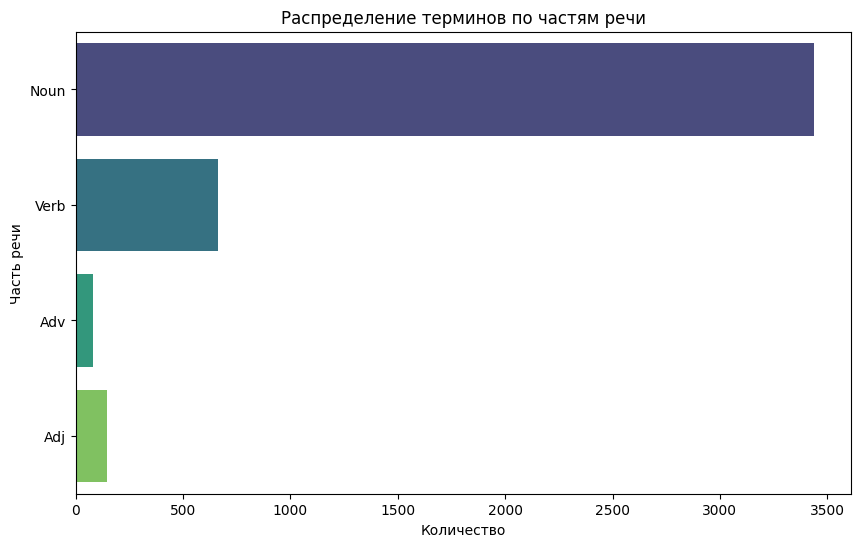

In [48]:
#визуализация частей речи
plt.figure(figsize=(10, 6))
sns.countplot(y='pos', data=df, palette='viridis')
plt.title('Распределение терминов по частям речи')
plt.xlabel('Количество')
plt.ylabel('Часть речи')
plt.show()

In [49]:
#==== ЧАСТОТНЫЙ АНАЛИЗ ПО КЛАССАМ ====
from nltk import FreqDist

cnt = Counter()
for text in df["text_ready"]:
    for word in text.split():
        cnt[word] += 1
print(cnt.most_common(20))

#hазделяем корпус по меткам
teen_tokens = [w for toks in df.loc[df["label"] == "Teen", "tokens"] for w in toks]
parent_tokens = [w for toks in df.loc[df["label"] == "Parents", "tokens"] for w in toks]

freq_teen = FreqDist(teen_tokens)
freq_parent = FreqDist(parent_tokens)
print(freq_teen.most_common(20))
print(freq_parent.most_common(20))

[('воспитание', 30), ('обучения', 27), ('социальная', 27), ('педагогическая', 25), ('образования', 24), ('деятельность', 23), ('реабилитация', 23), ('реабилитации', 18), ('система', 17), ('личности', 17), ('психология', 17), ('педагогика', 17), ('обучение', 17), ('метод', 16), ('воспитания', 16), ('нарушение', 16), ('развитие', 15), ('профессиональная', 14), ('развития', 14), ('работа', 13)]
[]
[]


In [50]:
print(df['label'].unique())

['prof' 'slang']


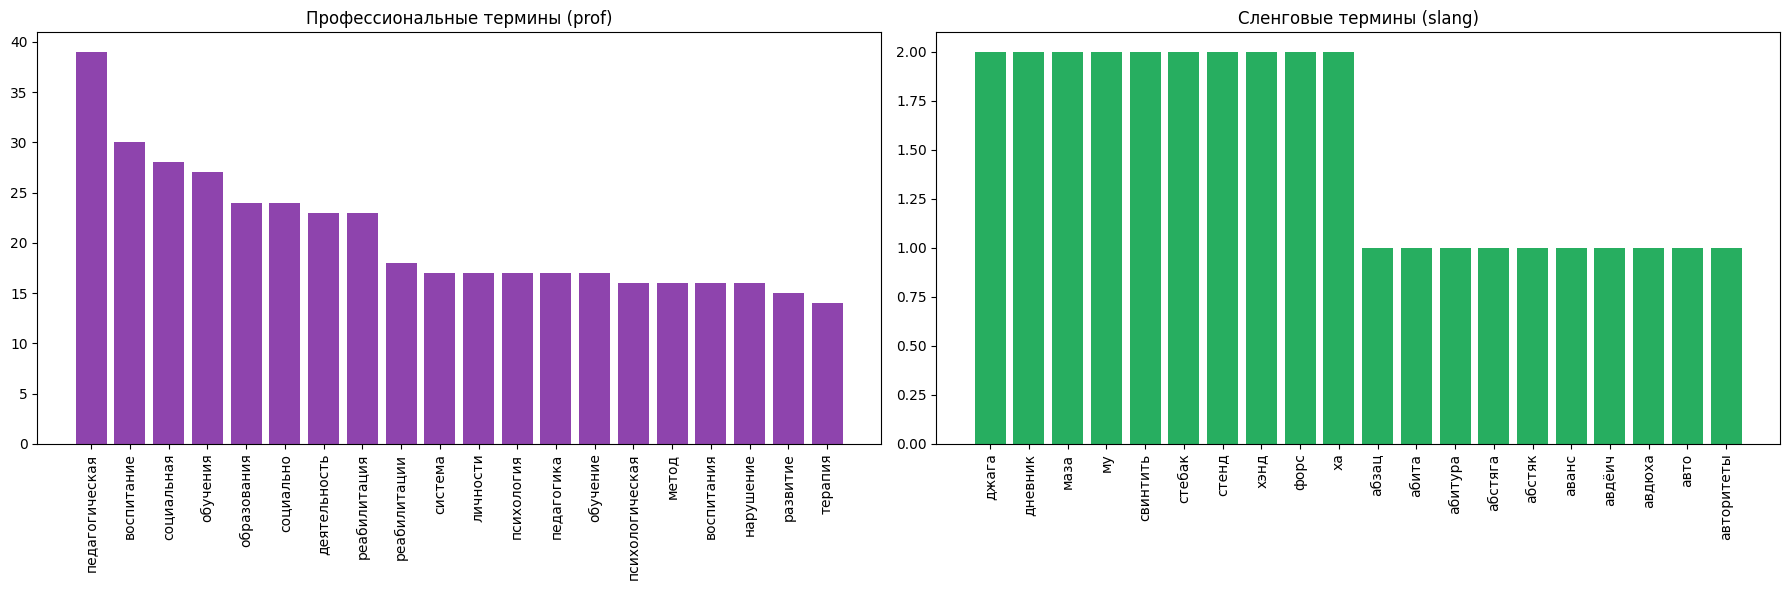

In [51]:
#==== ВИЗУАЛИЗАЦИЯ ====
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

#график для подростков
prof_common = freq_prof.most_common(20)
if len(prof_common) > 0:
    prof_words = [item[0] for item in prof_common]
    prof_counts = [item[1] for item in prof_common]
    axes[0].bar(prof_words, prof_counts, color='#8E44AD')
    axes[0].set_title("Профессиональные термины (prof)")
    axes[0].tick_params(axis='x', rotation=90)

#рафик для родителей
slang_common = freq_slang.most_common(20)
if len(slang_common) > 0:
    slang_words = [item[0] for item in slang_common]
    slang_counts = [item[1] for item in slang_common]
    axes[1].bar(slang_words, slang_counts, color='#27AE60')
    axes[1].set_title("Сленговые термины (slang)")
    axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.savefig("freq_plots_prof_slang.png", dpi=150)
plt.show()

[('педагогический', 64), ('социальный', 52), ('воспитание', 48), ('обучение', 48), ('реабилитация', 41), ('развитие', 34), ('образование', 32), ('деятельность', 31), ('профессиональный', 25), ('процесс', 23), ('метод', 23), ('образовательный', 22), ('дети', 22), ('в', 22), ('нарушение', 22), ('система', 20), ('работа', 20), ('педагогика', 20), ('личность', 19), ('психология', 18)]


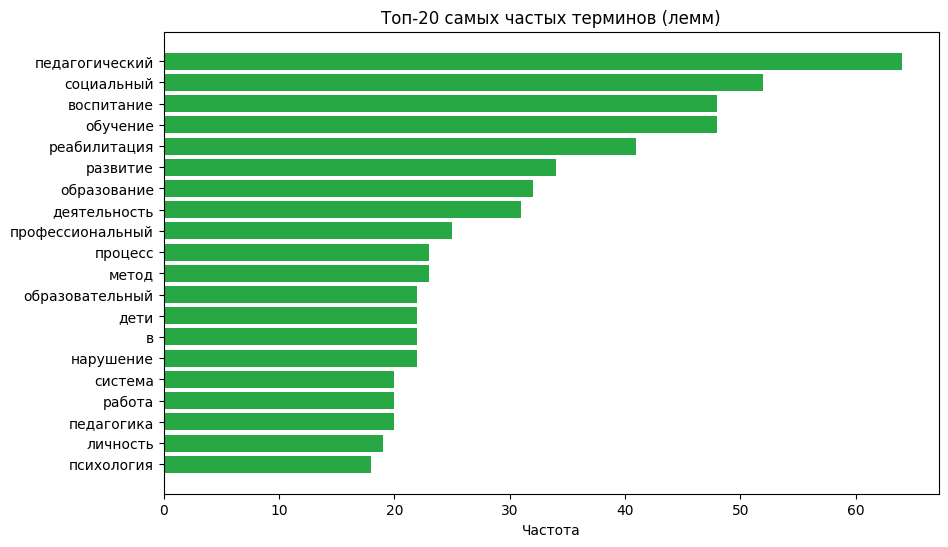

In [52]:
#==== ТОП-20 САМЫХ ЧАСТЫХ СЛОВ В ЛЕММАХ ====
cnt = Counter()
for text in df["text_lemmas"]:
    for word in text.split():
        cnt[word] += 1
print(cnt.most_common(20))

# Визуализация топ-20 частых слов
top_words = cnt.most_common(20)
words = [w[0] for w in top_words]
counts = [w[1] for w in top_words]

plt.figure(figsize=(10, 6))
plt.barh(words, counts, color='#28A745')
plt.title('Топ-20 самых частых терминов (лемм)')
plt.xlabel('Частота')
plt.gca().invert_yaxis()
plt.show()

In [53]:
#==== WORD2VEC ====
#оборачиваем список токенов в нужный формат
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

sentences = df['tokens'].tolist()
w2v_model = Word2Vec(
    min_count=2,
    window=5,
    vector_size=100,
    negative=10,
    alpha=0.03,
    min_alpha=0.0007,
    sample=6e-5,
    sg=1
)

w2v_model.build_vocab(sentences)
w2v_model.train(sentences, total_examples=w2v_model.corpus_count, epochs=10, report_delay=1)

w2v_model.wv.most_similar(positive=["аутизм"], topn=5)
w2v_model.wv.most_similar(positive=["адаптация"], topn=5)
w2v_model.wv.most_similar(positive=["воспитание"], topn=5)

[('субкультура', 0.3637917935848236),
 ('результата', 0.21864637732505798),
 ('управленческое', 0.2159946858882904),
 ('программы', 0.21442683041095734),
 ('воздействие', 0.21329741179943085)]

In [54]:
#========== Bag of Words ============
#Bag of Words используем леммы
bow_vectorizer = CountVectorizer()
bow_model = bow_vectorizer.fit_transform(df['text_lemmas'])
print(bow_model.shape)


(4331, 3942)


In [55]:
#========== TF-IDF ==================
tfidf_vectorizer = TfidfVectorizer()
tfidf_model = tfidf_vectorizer.fit_transform(df['text_lemmas'])
print(tfidf_model.shape)

(4331, 3942)


In [56]:
!pip install bertopic

In [57]:
# ===== СОЗДАЕМ И ОБУЧАЕМ МОДЕЛЬ BERTopic =====
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

In [58]:
# загружаем модель для эмбеддингов (она переводит слова в числа)
sentence_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [60]:
#создаем векторizer со стоп-словами
# берем стандартные русские стоп-слова из nltk
stop_words = stopwords.words("russian")
vectorizer_model = CountVectorizer(stop_words=stop_words)

#загружаем модель для эмбеддингов
sentence_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [61]:
#создаем саму модель BERTopic
#передаем ей нашу модель для эмбеддингов и векторizer для стоп-слов
topic_model = BERTopic(
    embedding_model=sentence_model,
    vectorizer_model=vectorizer_model, #CountVectorizer со стоп-словами из твоего кода
    language="russian",
    calculate_probabilities=True,
    verbose=True
)

In [65]:
print(df.columns.tolist())

['text', 'pos', 'lemma', 'label', 'text_ready', 'tokens', 'text_lemmas']


In [66]:
# берем  тексты (колонка 'stem' из датасета)
docs = df['text'].values.tolist()

# обучаем модель
topics, probs = topic_model.fit_transform(docs)

2026-11-26 03:42:36,883 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/136 [00:00<?, ?it/s]

2026-11-26 03:43:37,977 - BERTopic - Embedding - Completed ✓
2026-11-26 03:43:37,979 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-26 03:45:03,698 - BERTopic - Dimensionality - Completed ✓
2026-11-26 03:45:03,700 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-26 03:45:05,576 - BERTopic - Cluster - Completed ✓
2026-11-26 03:45:05,586 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-26 03:45:05,697 - BERTopic - Representation - Completed ✓


In [67]:
# смотрим какие темы нашлись
freq = topic_model.get_topic_info()
print(freq.head(10))

   Topic  Count                                              Name  \
0     -1   1723  -1_воспитание_дошкольного_педагогика_образования   
1      0    478      0_цепануть_хильнуть_фурычить_фунициклировать   
2      1    112             1_артуха_аршин_астереогнозия_бабульки   
3      2    107                      2_джага_бабаха_алалия_берёза   
4      3    103                   3_свинтить_ананас_балдоны_башли   
5      4     77          4_социальная_социально_социальной_медико   
6      5     71                5_ортопедическая_обувь_тела_брусок   
7      6     68                             6_му_ха_авдюха_амнуха   
8      7     62               7_болезни_болезнь_дистрофия_синдром   
9      8     59                  8_башлить_башлёвый_башня_василёк   

                                      Representation  \
0  [воспитание, дошкольного, педагогика, образова...   
1  [цепануть, хильнуть, фурычить, фунициклировать...   
2  [артуха, аршин, астереогнозия, бабульки, бабёш...   
3  [джага, бабах

In [68]:
#строим графики
#график топ 10 тем
fig1 = topic_model.visualize_barchart(top_n_topics=10)
fig1.show()
#график расстояний между темами (карта)
fig2 = topic_model.visualize_topics()
fig2.show()
# смотрим какие слова входят в самую популярную тему (без -1, это выбросы)
print(topic_model.get_topic(0)) # 0 - это номер темы

[('цепануть', np.float64(0.009129222155570585)), ('хильнуть', np.float64(0.009129222155570585)), ('фурычить', np.float64(0.009129222155570585)), ('фунициклировать', np.float64(0.009129222155570585)), ('финишировать', np.float64(0.009129222155570585)), ('фейсовать', np.float64(0.009129222155570585)), ('фачиться', np.float64(0.009129222155570585)), ('фачить', np.float64(0.009129222155570585)), ('факушки', np.float64(0.009129222155570585)), ('факнуться', np.float64(0.009129222155570585))]
